## MTL Trajet: 07 Usage Mode Distance Time Patterns (Flag 7)

### Dataset Overview
MTL urban trajectories with trip usage, mode, departure timing, distance, duration, endpoints, and point-level speed information.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Based on trajectories with different usages, analyze the relationship between usages and other attributes

Role: Urban trajectory analyst


Category: Trip usage, transport mode, distance, duration, and departure time

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which usages have the highest motor-vehicle reliance, and how does education compare?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

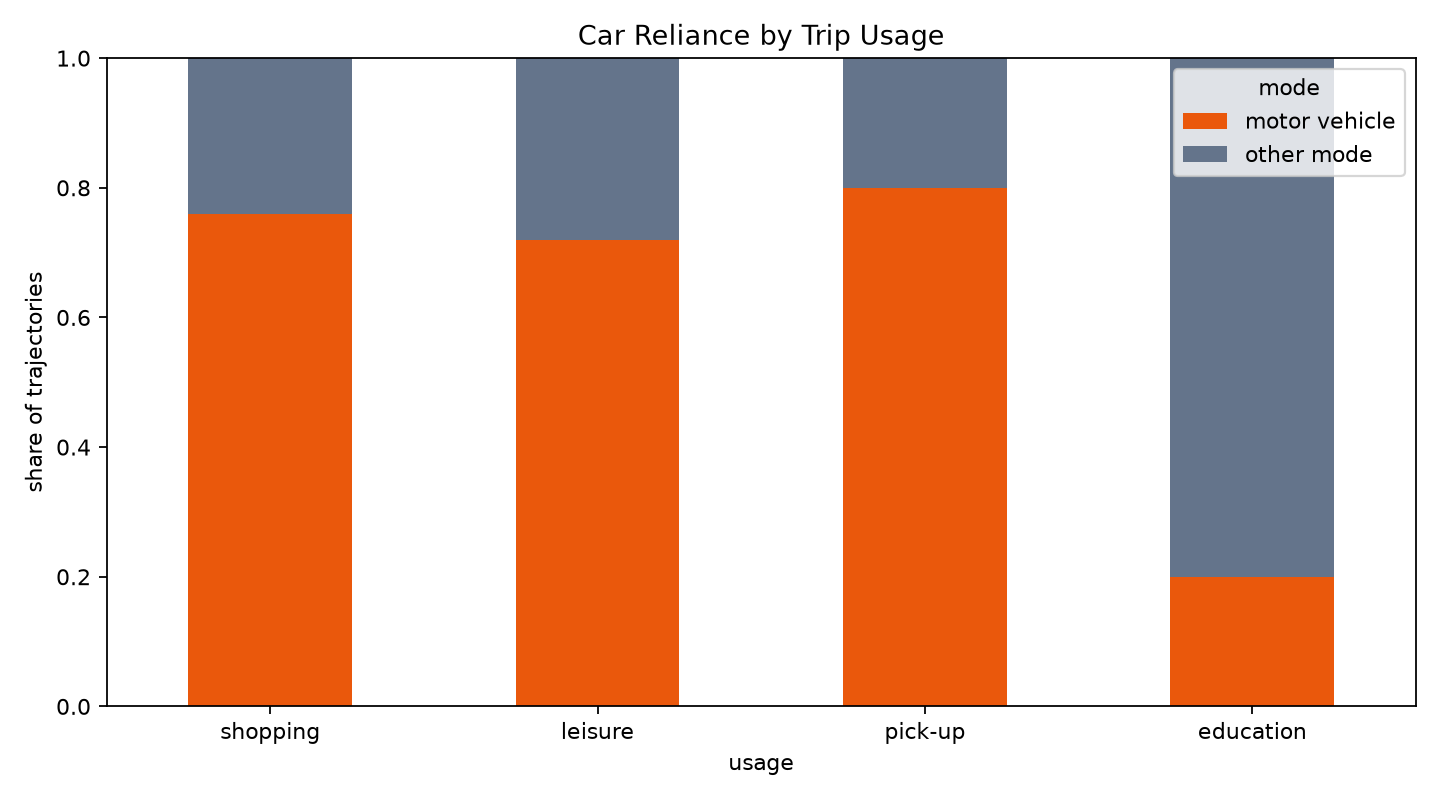

In [ ]:
pd.crosstab(df.usage, df.mode_group, normalize='index')
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/mode_by_usage.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "usage_mode_comparison",
  "insight": "Shopping, leisure, and pick-up trips show greater motor-vehicle reliance than education trips.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Car Reliance by Trip Usage",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/mode_by_usage.png"
  },
  "question": "Which usages have the highest motor-vehicle reliance, and how does education compare?",
  "code": "pd.crosstab(df.usage, df.mode_group, normalize='index')",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "transport_mode",
    "trajectory_id"
  ]
}

### **Question 2**: How do pick-up trip distances and duration distributions compare with those of other usages?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

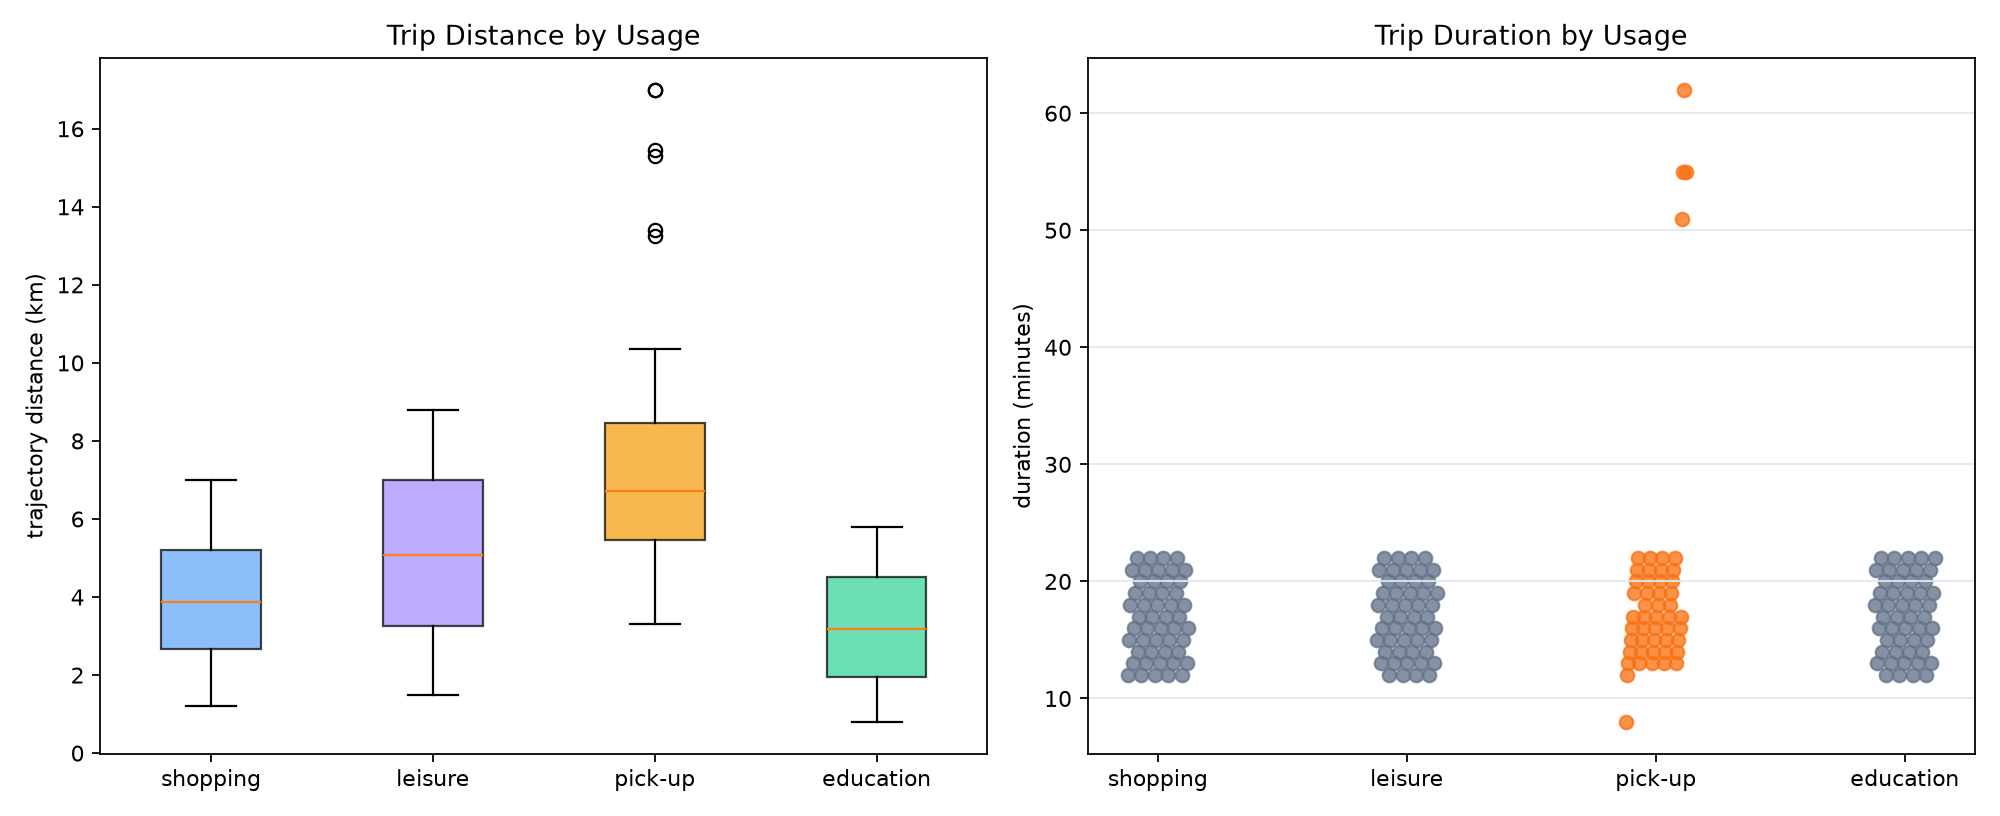

In [ ]:
df.groupby('usage')[['distance_km','duration_minutes']].agg(['mean','median','min','max'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/pickup_distance_duration.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "usage_distance_duration",
  "insight": "Trips for pick-up sustain relatively longer distances than other usages, but a few outliers with very long durations exist.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Pick-up Distance and Duration",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/pickup_distance_duration.png"
  },
  "question": "How do pick-up trip distances and duration distributions compare with those of other usages?",
  "code": "df.groupby('usage')[['distance_km','duration_minutes']].agg(['mean','median','min','max'])",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Which usage has the most concentrated departure-time pattern, and when do the other usages occur?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

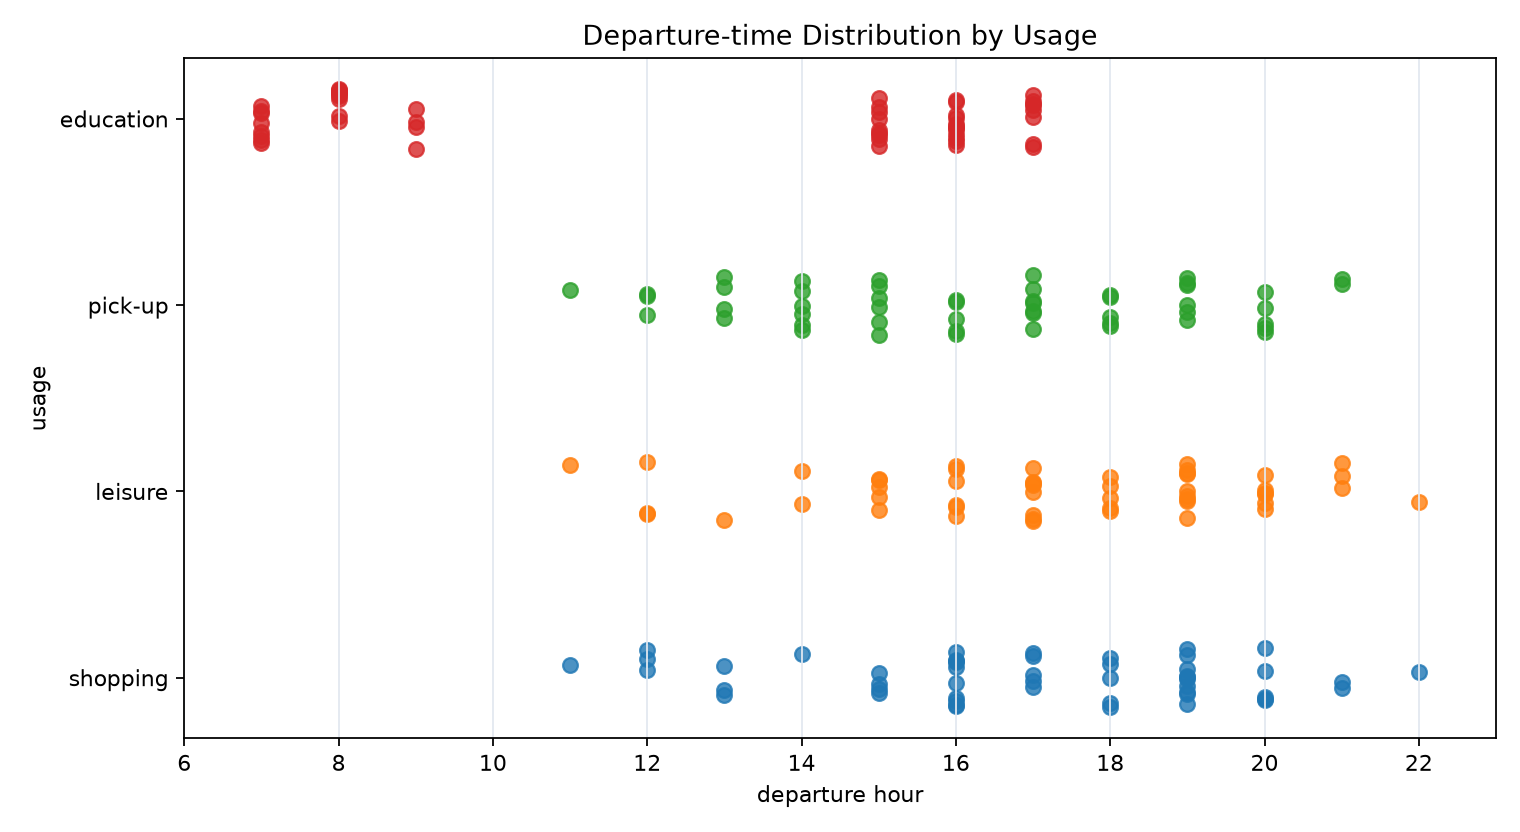

In [ ]:
df.groupby('usage').start_hour.agg(['min','median','max','nunique'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/departure_time_by_usage.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "usage_departure_time",
  "insight": "Education trips are concentrated in fixed morning and afternoon windows, whereas the other usages are more dispersed across the afternoon and evening.",
  "insight_type": "group_comparison",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Departure-time Distribution by Usage",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/departure_time_by_usage.png"
  },
  "question": "Which usage has the most concentrated departure-time pattern, and when do the other usages occur?",
  "code": "df.groupby('usage').start_hour.agg(['min','median','max','nunique'])",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 7)

Shopping, leisure, and pick-up trips have greater motor-vehicle reliance than education trips. Pick-up trips are relatively longer, with a small set of long-duration records forming the upper duration tail. Education trips occur in fixed morning and afternoon windows, whereas the other usages are more dispersed across the afternoon and evening.